# Day 1 - Data foundations practical tasks
***

These tasks cover data preparation, visualization and feature engineering topics.

## Explore the datasets and answer the questions below.
#### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

For this task you will use red wine dataset

In [263]:
import pandas as pd
import numpy as np
wine_data = pd.read_csv('winequality-red.csv', sep = ';')
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [264]:
wine_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [265]:
wine_data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [266]:
wine_data.isnull().values.sum()

np.int64(0)

### 1. `quality` attribute in the DataFrame has a score from 0 to 10. How many observations (rows) belong to each score level? 

In [267]:
wine_data.groupby('quality').size()

quality
3     10
4     53
5    681
6    638
7    199
8     18
dtype: int64

### 2. Make a bar plot, where we can see distribution of the samples against quality attributes.

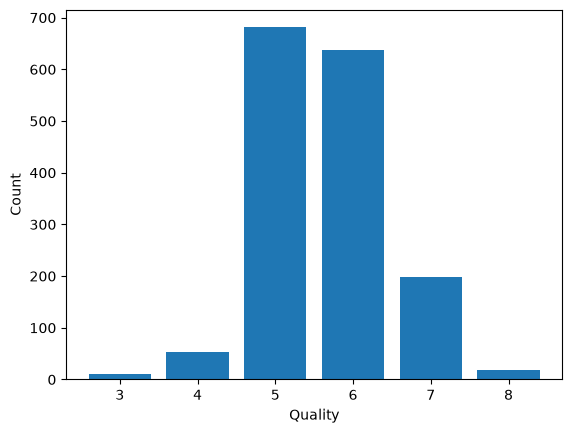

In [268]:
import matplotlib.pyplot as plt

plt.bar(wine_data['quality'].unique(), wine_data['quality'].value_counts())
plt.xlabel("Quality")
plt.ylabel("Count")
plt.show()

### 3. What is the average value of each feature (column) in each `quality` score level? 

In [269]:
wine_data.groupby('quality').mean()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.360000,0.884500,0.171000,2.635000,0.122500,11.000000,24.900000,0.997464,3.398000,0.570000,9.955000
4,7.779245,0.693962,0.174151,2.694340,0.090679,12.264151,36.245283,0.996542,3.381509,0.596415,10.265094
5,8.167254,0.577041,0.243686,2.528855,0.092736,16.983847,56.513950,0.997104,3.304949,0.620969,9.899706
6,8.347179,0.497484,0.273824,2.477194,0.084956,15.711599,40.869906,0.996615,3.318072,0.675329,10.629519
7,8.872362,0.403920,0.375176,2.720603,0.076588,14.045226,35.020101,0.996104,3.290754,0.741256,11.465913
8,8.566667,0.423333,0.391111,2.577778,0.068444,13.277778,33.444444,0.995212,3.267222,0.767778,12.094444


### 4. What is the median value of each feature (column) in each `quality` score level? 

In [270]:
wine_data.groupby('quality').median()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,7.50,0.845,0.035,2.1,0.0905,6.0,15.0,0.997565,3.39,0.545,9.925
4,7.50,0.670,0.090,2.1,0.0800,11.0,26.0,0.996500,3.37,0.560,10.000
5,7.80,0.580,0.230,2.2,0.0810,15.0,47.0,0.997000,3.30,0.580,9.700
6,7.90,0.490,0.260,2.2,0.0780,14.0,35.0,0.996560,3.32,0.640,10.500
7,8.80,0.370,0.400,2.3,0.0730,11.0,27.0,0.995770,3.28,0.740,11.500
8,8.25,0.370,0.420,2.1,0.0705,7.5,21.5,0.994940,3.23,0.740,12.150


### 5. We can notice that for some features raw values differ significantly. Scale the data (except quality column) using Min-Max Scaling manually (create formula yourself). Then use built-in Min-Max Scaling function to validate results (display the resulting data frames separately).
#### Hint: you can use `pd.DataFrame(<your data>)` to display the result of the built-in function in a nicer way.

In [271]:
from sklearn.preprocessing import MinMaxScaler

features = wine_data.drop(columns=['quality'])
scaled_df = (features - features.min()) / (features.max() - features.min())
display(scaled_df.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846


In [272]:
scaler = MinMaxScaler()
builtin_scaled_array = scaler.fit_transform(features)
builtin_scaled_df = pd.DataFrame(builtin_scaled_array, columns=features.columns)
display(builtin_scaled_df.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846


### 6. Create correlation matrix between all variables.

In [273]:
import seaborn as sns

corr = builtin_scaled_df.select_dtypes(include=['number']).corr()
corr

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595


### 7. Plot heatmap to see correlations.

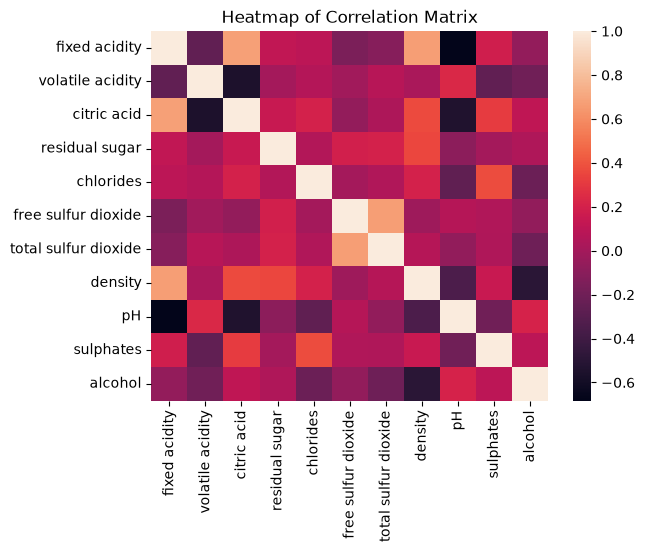

In [ ]:
sns.heatmap(corr)
plt.title("Heatmap of Correlation Matrix")
plt.show()

### 8. Identify potential outliers in `alcohol` using the IQR rule. Flag values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

In [275]:
q1 = wine_data['alcohol'].quantile(0.25)
q3 = wine_data['alcohol'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

alcohol_outliers = wine_data.loc[
    (wine_data['alcohol'] < lower_fence) | (wine_data['alcohol'] > upper_fence),
    ['alcohol']
].sort_values('alcohol')

print(f"Lower fence: {lower_fence:,.2f}")
print(f"Upper fence: {upper_fence:,.2f}")
alcohol_outliers

Lower fence: 7.10
Upper fence: 13.50


,alcohol
1475,13.566667
1114,13.600000
1228,13.600000
1132,13.600000
1477,13.600000
588,14.000000
142,14.000000
144,14.000000
1270,14.000000
821,14.000000


### 9. Plot boxplots for all columns (except quality), use figure size 15x6. You can use both original and scaled data for this task. Try to interpret the data for one feature of your choice and write your observations.

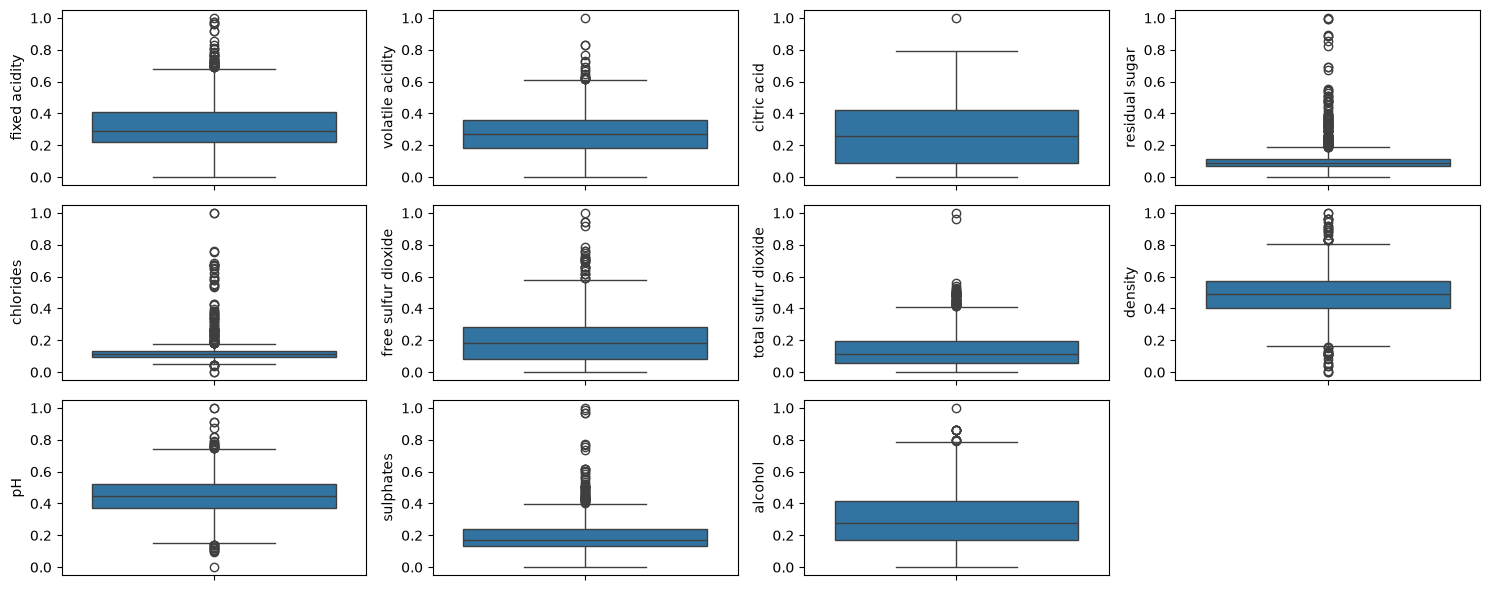

In [276]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 6))
axes = axes.flatten()

for idx, feature in enumerate(features.columns):
    ax = axes[idx]
    sns.boxplot(y=builtin_scaled_df[feature], ax=ax)

for idx in range(len(features.columns), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

Observation of residual sugar: Low median, majority of wines have low residual sugar. We can see alot of outliers of sweet wine.

### 10. Plot boxplot of Ph for each quality type.

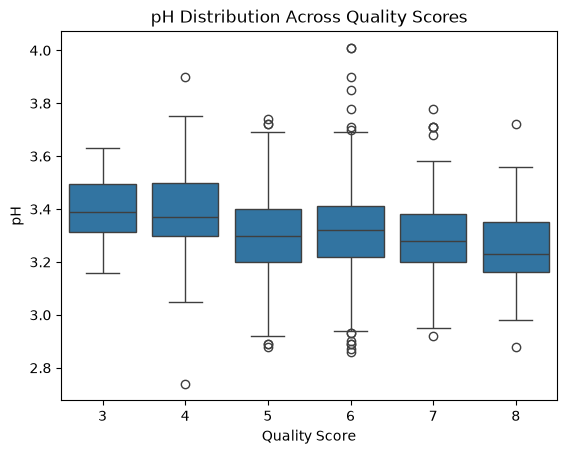

In [277]:
sns.boxplot(x='quality', y='pH', data=wine_data)

plt.xlabel("Quality Score")
plt.ylabel("pH")
plt.title("pH Distribution Across Quality Scores")
plt.show()

### 11. Plot a scatter plot of `quality` against the feature with the strongest correlation to it. Does alcohol content appear associated with wine quality?

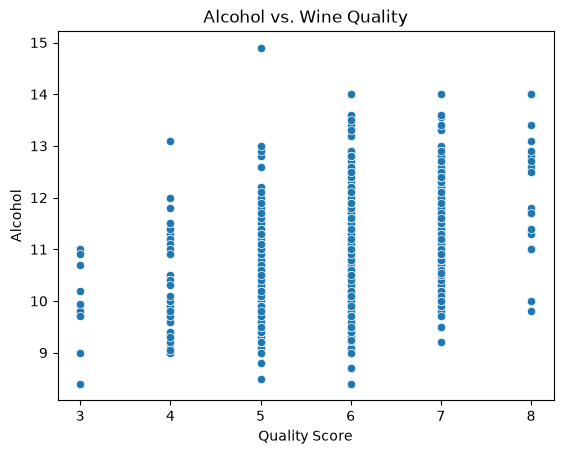

In [278]:
sns.scatterplot(x='quality', y='alcohol', data=wine_data)

plt.xlabel("Quality Score")
plt.ylabel("Alcohol")
plt.title("Alcohol vs. Wine Quality")
plt.show()

### 12. Plot scatter plot for any two columns and color it by `quality` number. Add color legend and write your observations.

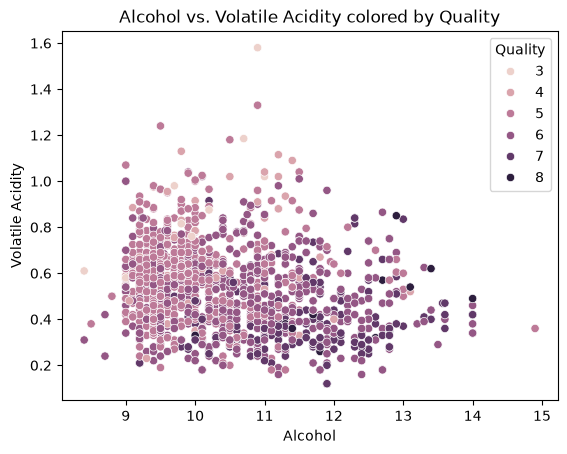

In [ ]:
scatter = sns.scatterplot(
    x='alcohol', 
    y='volatile acidity', 
    hue='quality',
    data=wine_data, 
)

plt.xlabel("Alcohol")
plt.ylabel("Volatile Acidity")
plt.title("Alcohol vs. Volatile Acidity colored by Quality")

plt.legend(title='Quality')
plt.show()

### 13. Create X, y for independent variables (all except `quality`) and target variable `quality`, perform k-fold k=3 split on them and calculate and print out the length of training set and testing set for each fold

In [280]:
from sklearn.model_selection import KFold

X = wine_data.drop(columns=['quality'])
y = wine_data['quality']

kf = KFold(n_splits=3, shuffle=True, random_state=42)

In [281]:
fold = 1

for train_index, test_index in kf.split(X):
    if fold == 1:
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]
        print(f"X_train shape: {X_train.shape}")
        print(f"y_train shape: {y_train.shape}")
        print(f"X_test shape: {X_test.shape}")
        print(f"y_test shape: {y_test.shape}\n")
        break
    
    fold += 1

X_train shape: (1066, 11)
y_train shape: (1066,)
X_test shape: (533, 11)
y_test shape: (533,)



### 14. Create two new features:
- Sulfur dioxide ratio (`free sulfur dioxide` / `total sulfur dioxide`)
- Total acidity (`fixed acidity` + `volatile acidity` + `citric acid`)

In [282]:
wine_data['sulfur dioxide ratio'] = wine_data['free sulfur dioxide'] / wine_data['total sulfur dioxide']
wine_data['total acidity'] = wine_data['fixed acidity'] + wine_data['volatile acidity'] + wine_data['citric acid']

print(wine_data[['sulfur dioxide ratio', 'total acidity']].head())

   sulfur dioxide ratio  total acidity
0              0.323529           8.10
1              0.373134           8.68
2              0.277778           8.60
3              0.283333          12.04
4              0.323529           8.10


### 15. Create a sample dataset with dates for a whole week. Extract day of the week with `dayofweek` function (0=Monday, 6=Sunday). Additionally flag weekends by creating another new `is_weekend` feature.

In [283]:
weeks = pd.DataFrame({'date': pd.date_range(start='2026-10-01', periods=7, freq='D')})
weeks['day_of_week'] = weeks['date'].dt.dayofweek
weeks['is_weekend'] = weeks['day_of_week'].isin([5, 6])
print(weeks)

        date  day_of_week  is_weekend
0 2026-10-01            3       False
1 2026-10-02            4       False
2 2026-10-03            5        True
3 2026-10-04            6        True
4 2026-10-05            0       False
5 2026-10-06            1       False
6 2026-10-07            2       False


C:\Users\kristupas.paulauskas\AppData\Local\Temp\ipykernel_24332\405397801.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weeks['day_of_week'] = weeks['date'].dt.dayofweek
